In [1]:
!pip install xgboost lightgbm catboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [2]:
df = pd.read_csv('/content/diabetes_patients_10000_full.csv')
df

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic
...,...,...,...,...,...,...,...,...,...,...
9995,9996,52.0,Female,248.0,1.03,33.1,38.0,271.0,5.3,Diabetic
9996,9997,71.0,Male,111.0,0.92,31.3,40.0,158.0,6.7,Diabetic
9997,9998,49.0,Female,230.0,0.67,26.0,48.0,180.0,10.5,Diabetic
9998,9999,22.0,Male,184.0,0.91,26.1,19.0,195.0,6.1,Diabetic


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [4]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [5]:
df.isnull().sum()

,0
Patient_ID,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.drop('Patient_ID',axis=1,inplace=True)

In [8]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df[['Gender']] = imputer.fit_transform(df[['Gender']])

cols = ['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol']
impute = SimpleImputer(missing_values=np.nan, strategy='median')
for i in cols:
  df[[i]] = impute.fit_transform(df[[i]])

In [9]:
df.isnull().sum()

,0
Age,0
Gender,0
Blood_Sugar_Level,0
Creatinine,0
BMI,0
Urea,0
Cholesterol,0
HbA1c,0
Class,0


In [10]:
df.reset_index(drop=True,inplace=True)

<Axes: xlabel='BMI', ylabel='Density'>

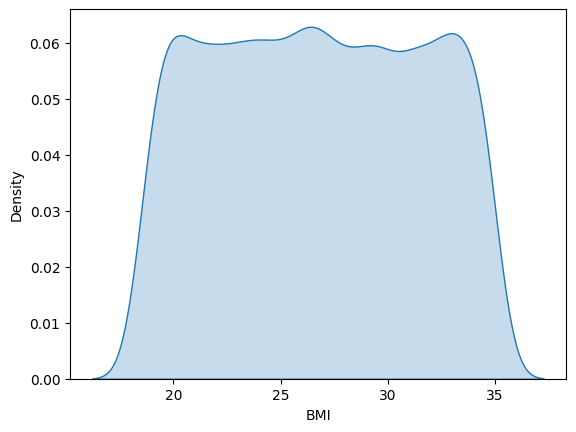

In [11]:
sns.kdeplot(data=df,x='BMI',fill=True)

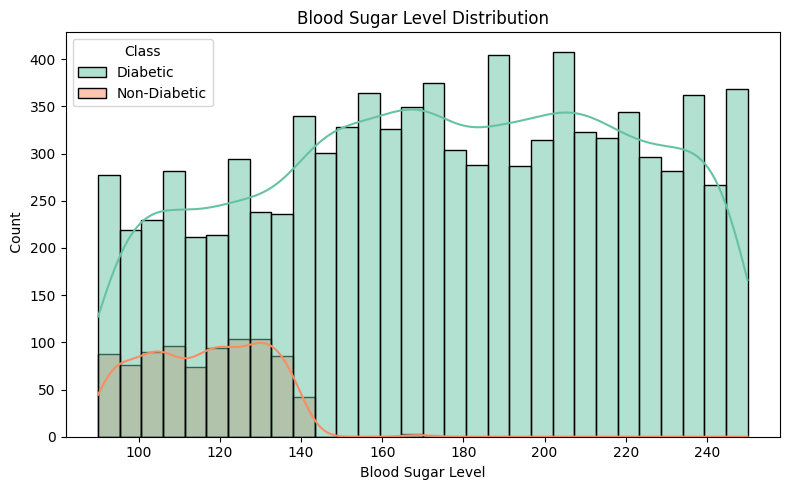

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Blood_Sugar_Level', hue='Class', kde=True, bins=30, palette='Set2')
plt.title('Blood Sugar Level Distribution', fontsize=12)
plt.xlabel('Blood Sugar Level')
plt.ylabel(' Count')
plt.tight_layout()
plt.show()

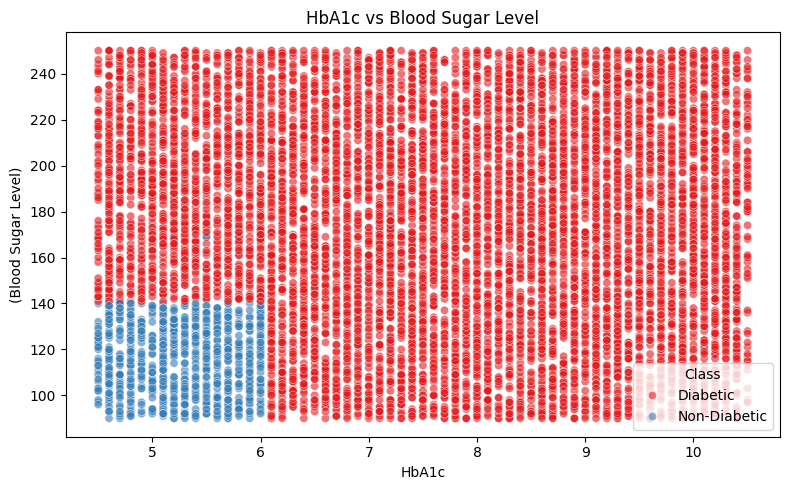

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='HbA1c', y='Blood_Sugar_Level', hue='Class', alpha=0.6, palette='Set1')
plt.title('HbA1c vs Blood Sugar Level', fontsize=12)
plt.xlabel('HbA1c')
plt.ylabel('(Blood Sugar Level)')
plt.tight_layout()
plt.show()

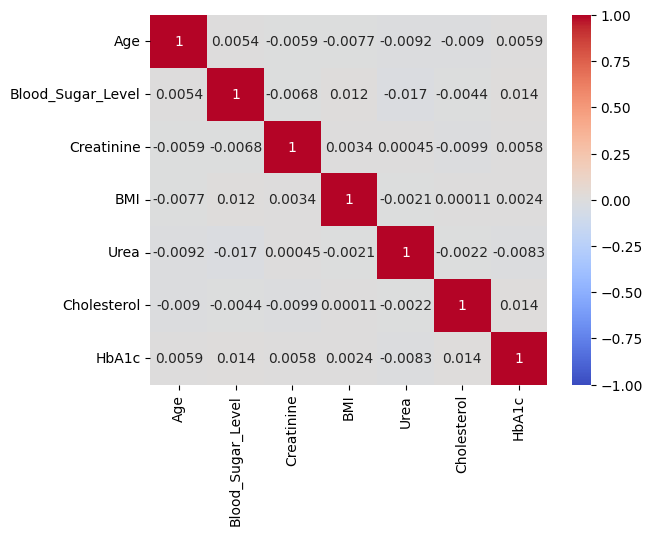

In [14]:
corr = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    corr, annot=True,
    cmap="coolwarm", vmin=-1, vmax=1
)
plt.show()

/tmp/ipykernel_47733/1470497367.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='HbA1c', ax=axes[0, 0], palette='Pastel1')
/tmp/ipykernel_47733/1470497367.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='Blood_Sugar_Level', ax=axes[0, 1], palette='Pastel1')
/tmp/ipykernel_47733/1470497367.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='BMI', ax=axes[1, 0], palette='Pastel1')
/tmp/ipykernel_47733/1470497367.py:12: FutureWarning: 

Passing `palette` without assignin

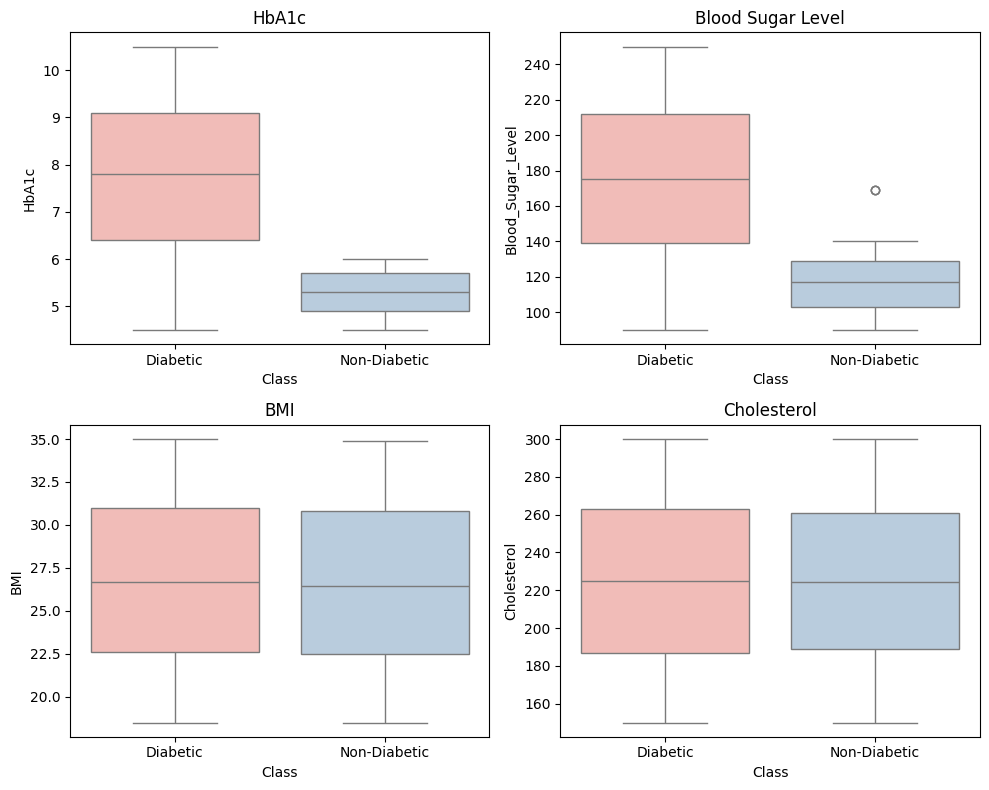

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.boxplot(data=df, x='Class', y='HbA1c', ax=axes[0, 0], palette='Pastel1')
axes[0, 0].set_title('HbA1c')

sns.boxplot(data=df, x='Class', y='Blood_Sugar_Level', ax=axes[0, 1], palette='Pastel1')
axes[0, 1].set_title('Blood Sugar Level')

sns.boxplot(data=df, x='Class', y='BMI', ax=axes[1, 0], palette='Pastel1')
axes[1, 0].set_title('BMI')

sns.boxplot(data=df, x='Class', y='Cholesterol', ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title('Cholesterol')

plt.tight_layout()
plt.show()

In [16]:
for i in df.select_dtypes('object').columns:
    print(f"Unique values in '{i}':", df[i].nunique())
    print('*' * 50)

Unique values in 'Gender': 2
**************************************************
Unique values in 'Class': 2
**************************************************


In [17]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')

ohe_encoded = ohe.fit_transform(df[['Gender']]).toarray()
ohe_df = pd.DataFrame(ohe_encoded, columns=ohe.get_feature_names_out(['Gender']),index=df.index)
df = pd.concat([df, ohe_df],axis=1)
df.drop('Gender',axis=1,inplace=True)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                10000 non-null  float64
 1   Blood_Sugar_Level  10000 non-null  float64
 2   Creatinine         10000 non-null  float64
 3   BMI                10000 non-null  float64
 4   Urea               10000 non-null  float64
 5   Cholesterol        10000 non-null  float64
 6   HbA1c              10000 non-null  float64
 7   Class              10000 non-null  object 
 8   Gender_Female      10000 non-null  float64
 9   Gender_Male        10000 non-null  float64
dtypes: float64(9), object(1)
memory usage: 781.4+ KB


In [19]:
x =df.drop('Class',axis=1)
y = df['Class']

In [20]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=100,stratify=None)

In [21]:
numcols = ['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol']
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train[numcols] = scaler.fit_transform(x_train[numcols])
x_test[numcols] = scaler.transform(x_test[numcols])

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, \
classification_report, confusion_matrix

results = []

model = LogisticRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred)
})

In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      1819
Non-Diabetic       0.86      0.83      0.85       181

    accuracy                           0.97      2000
   macro avg       0.92      0.91      0.92      2000
weighted avg       0.97      0.97      0.97      2000



In [24]:
!pip install imblearn
from imblearn.over_sampling import SMOTE
smote = SMOTE()
x_train_smote,y_train_smote = smote.fit_resample(x_train,y_train)
print('x_train_smote = ',x_train_smote.shape)
print('y_train_smote = ',y_train_smote.shape)

x_train_smote =  (14654, 9)
y_train_smote =  (14654,)


In [25]:
y_train_smote.value_counts()

,count
Class,
Diabetic,7327
Non-Diabetic,7327


In [26]:
model = LogisticRegression(class_weight='balanced')
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

results.append({
    'Method':'Class Weight Balancing',
    'Accuracy' : accuracy_score(y_test,y_pred)
})

In [27]:
model = LogisticRegression(class_weight={'Diabetic':1 ,'Non-Diabetic':4})
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

results.append({
    'Method':'Class Weight Balancing',
    'Accuracy' : accuracy_score(y_test,y_pred)
})


In [28]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Model,Accuracy
Method,,
NaN,Logistic Regression,0.9725
Class Weight Balancing,NaN,0.9500
Class Weight Balancing,NaN,0.9600


In [29]:
from sklearn.neighbors import KNeighborsClassifier

results = []
model = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1)

model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Acc_train = accuracy_score(y_train, y_pred_train)
Acc_test = accuracy_score(y_test, y_pred_test)

results.append({
    'Method':'KNN',
    'Accuracy' : Acc_test
})

In [30]:
print('Accuracy train :',Acc_train,'Accuracy test :',Acc_test)


Accuracy train : 0.984375 Accuracy test : 0.97


In [31]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

    Diabetic       0.99      0.96      0.98      1819
Non-Diabetic       0.71      0.93      0.81       181

    accuracy                           0.96      2000
   macro avg       0.85      0.95      0.89      2000
weighted avg       0.97      0.96      0.96      2000



In [32]:
from sklearn.naive_bayes import GaussianNB

model.fit(x_train,y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Acc_train = accuracy_score(y_train, y_pred_train)
Acc_test = accuracy_score(y_test, y_pred_test)

print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

    Diabetic       0.99      0.96      0.98      1819
Non-Diabetic       0.71      0.93      0.81       181

    accuracy                           0.96      2000
   macro avg       0.85      0.95      0.89      2000
weighted avg       0.97      0.96      0.96      2000



In [33]:
from sklearn.svm import SVC

model = SVC(C=0.1, kernel='linear',gamma="auto")
model.fit(x_train,y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [34]:
y_pred = model.predict(x_test)

In [35]:
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9735
              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.99      1819
Non-Diabetic       0.88      0.82      0.85       181

    accuracy                           0.97      2000
   macro avg       0.93      0.90      0.92      2000
weighted avg       0.97      0.97      0.97      2000



In [36]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [37]:
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='accuracy')

grid.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': ['auto', 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']},
             scoring='accuracy')

In [38]:
print(grid.best_params_)
print(grid.best_score_)

{'C': 100, 'gamma': 'auto', 'kernel': 'poly'}
0.9884999999999999


In [39]:
best_model = grid.best_estimator_

In [40]:
y_pred = best_model.predict(x_test)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.984
              precision    recall  f1-score   support

    Diabetic       0.99      0.99      0.99      1819
Non-Diabetic       0.91      0.92      0.91       181

    accuracy                           0.98      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.98      0.98      0.98      2000



In [41]:
!pip install -q gradio
import gradio as gr
import pandas as pd

def predict(glucose, bmi, blood_pressure, age, insulin, diabetes_pedigree):

    X_new = pd.DataFrame([[
        glucose, bmi, blood_pressure,
        age, insulin, diabetes_pedigree
    ]], columns=[
        'glucose', 'bmi', 'blood_pressure',
        'age', 'insulin', 'diabetes_pedigree'
    ])

    X_new = scaler.transform(X_new)
    prediction = best_model.predict(X_new)[0]

    return "Diabetic" if prediction == 1 else "Non-Diabetic"

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Number(label="Glucose"),
        gr.Number(label="BMI"),
        gr.Number(label="Blood Pressure"),
        gr.Number(label="Age"),
        gr.Number(label="Insulin"),
        gr.Number(label="Diabetes Pedigree")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Diabetes Risk Prediction",
    description="Enter patient data to predict the diabetes class."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3292967119c2916492.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [42]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1794   25]
 [  30  151]]


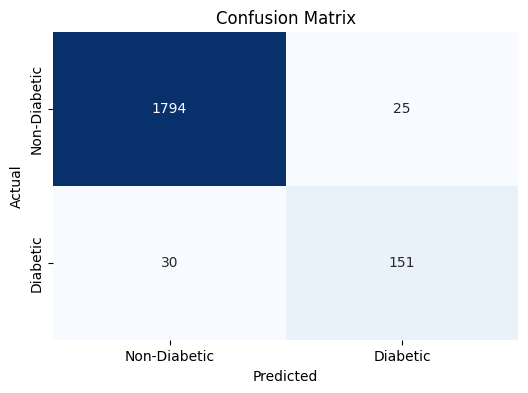


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.98      0.99      0.98      1819
    Diabetic       0.86      0.83      0.85       181

    accuracy                           0.97      2000
   macro avg       0.92      0.91      0.92      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.0076388277208957606


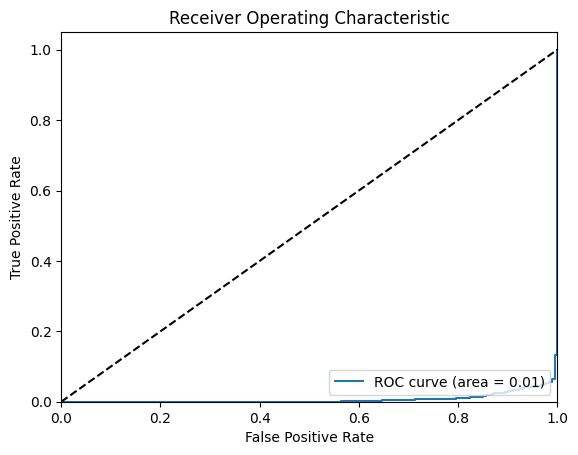

PR AUC: 0.7621761503389369


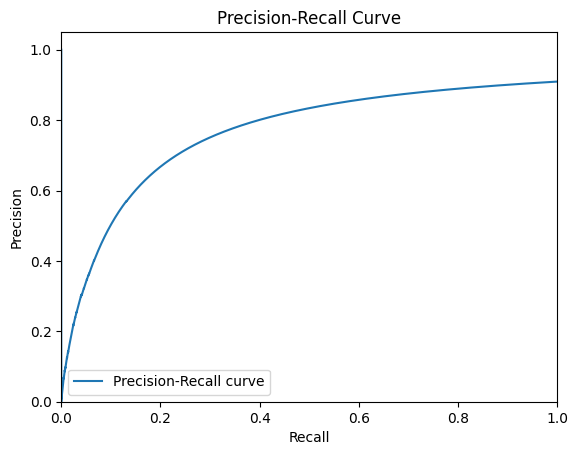

  8%|▊         | 1/13 [00:00<00:08,  1.36it/s]


Confusion Matrix:
 [[1797   22]
 [  36  145]]


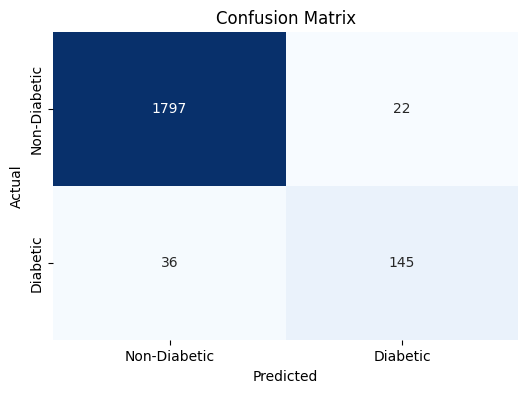


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.98      0.99      0.98      1819
    Diabetic       0.87      0.80      0.83       181

    accuracy                           0.97      2000
   macro avg       0.92      0.89      0.91      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.01620403415148265


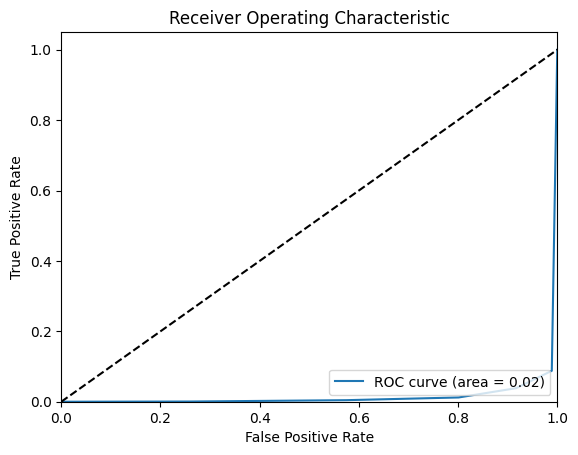

PR AUC: 0.8619795541244458


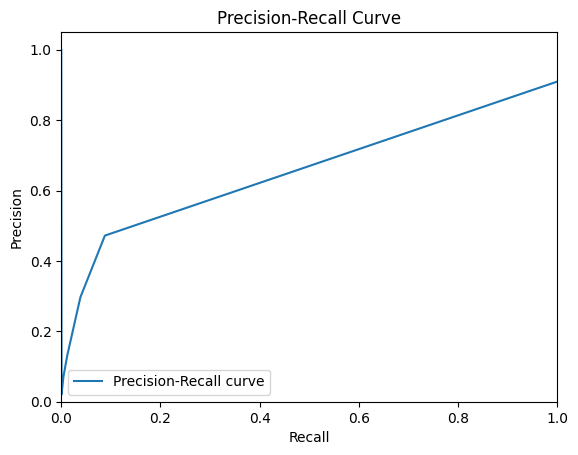

 15%|█▌        | 2/13 [00:02<00:11,  1.05s/it]


Confusion Matrix:
 [[1803   16]
 [  31  150]]


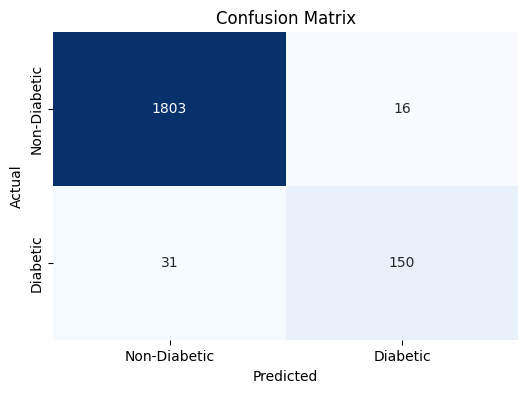


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.98      0.99      0.99      1819
    Diabetic       0.90      0.83      0.86       181

    accuracy                           0.98      2000
   macro avg       0.94      0.91      0.93      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.0058589656753908256


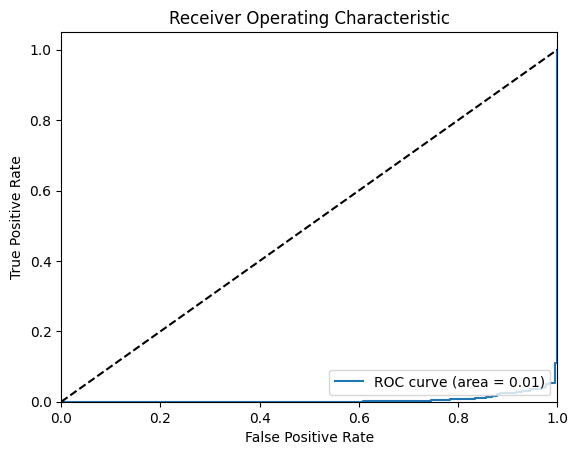

PR AUC: 0.7737239029878443


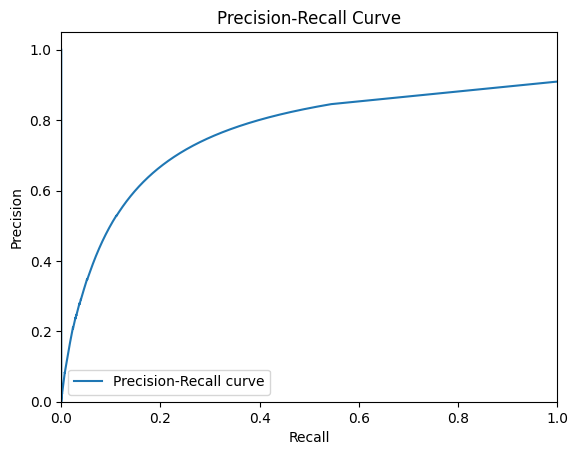

 23%|██▎       | 3/13 [00:05<00:22,  2.25s/it]


Confusion Matrix:
 [[1817    2]
 [   1  180]]


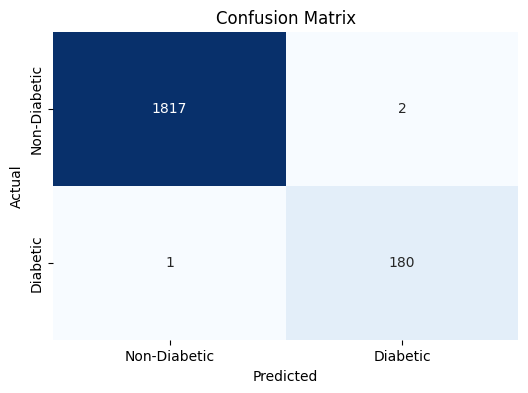


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       0.99      0.99      0.99       181

    accuracy                           1.00      2000
   macro avg       0.99      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.0033121835505514163


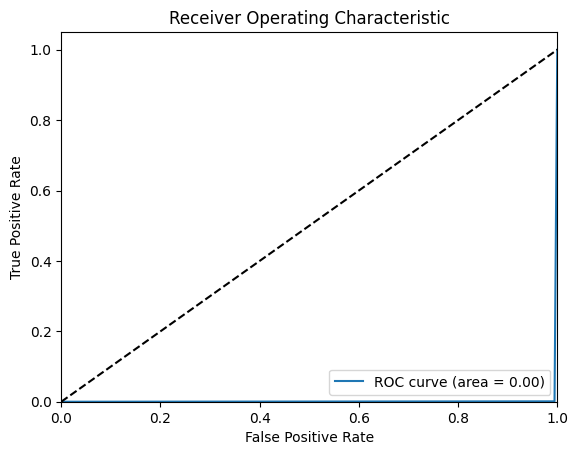

PR AUC: 0.9085120824749742


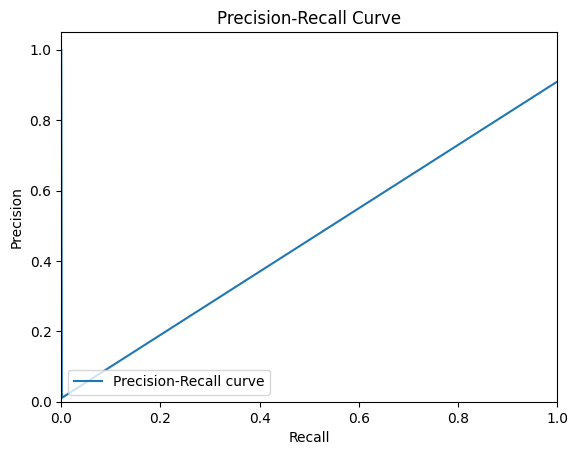

 31%|███       | 4/13 [00:06<00:15,  1.71s/it]


Confusion Matrix:
 [[1819    0]
 [  21  160]]


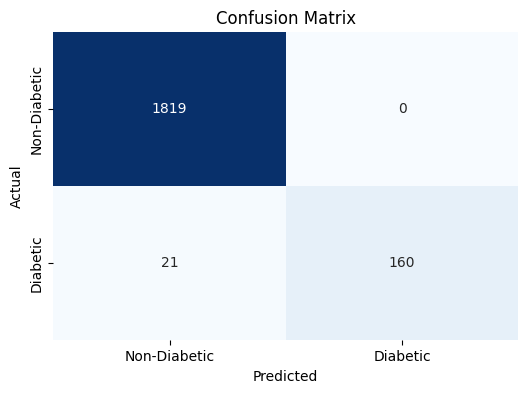


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.99      1.00      0.99      1819
    Diabetic       1.00      0.88      0.94       181

    accuracy                           0.99      2000
   macro avg       0.99      0.94      0.97      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.0012301094341800318


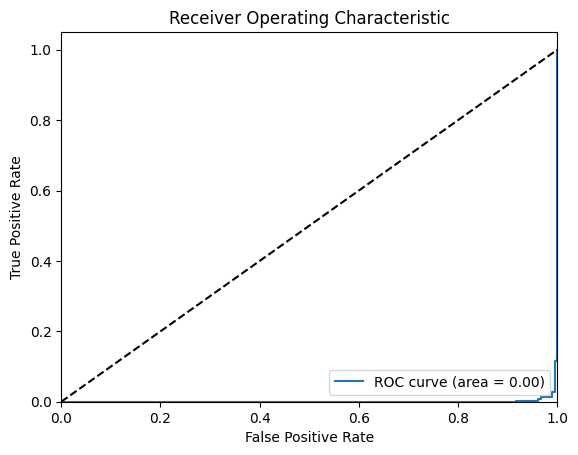

PR AUC: 0.761364574867205


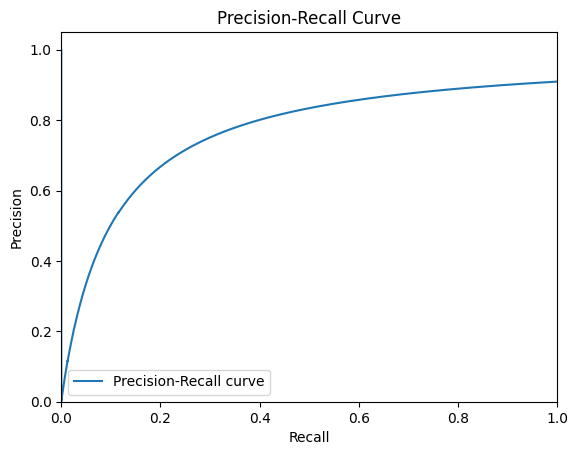

 38%|███▊      | 5/13 [00:07<00:12,  1.56s/it]


Confusion Matrix:
 [[1819    0]
 [   1  180]]


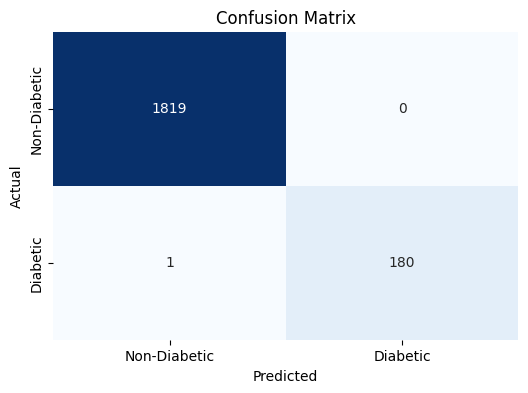


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.0007957744981609084


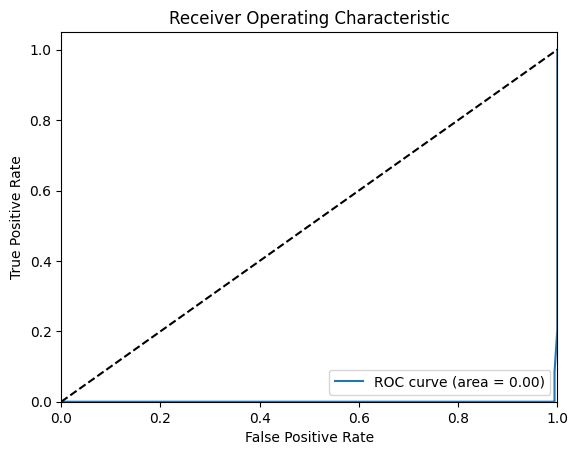

PR AUC: 0.8344169768991417


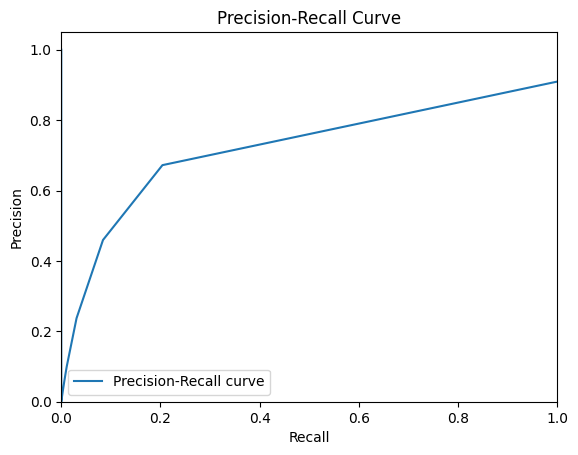

 46%|████▌     | 6/13 [00:10<00:14,  2.04s/it]


Confusion Matrix:
 [[1819    0]
 [   7  174]]


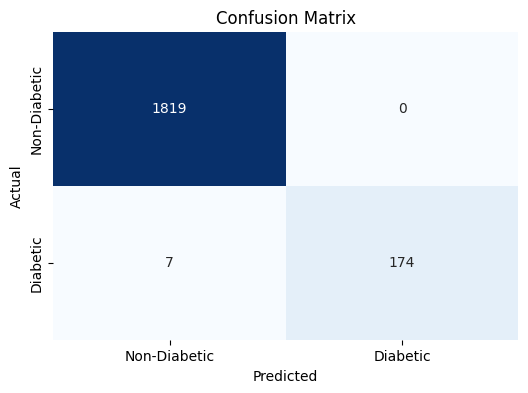


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.96      0.98       181

    accuracy                           1.00      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.000589237605508459


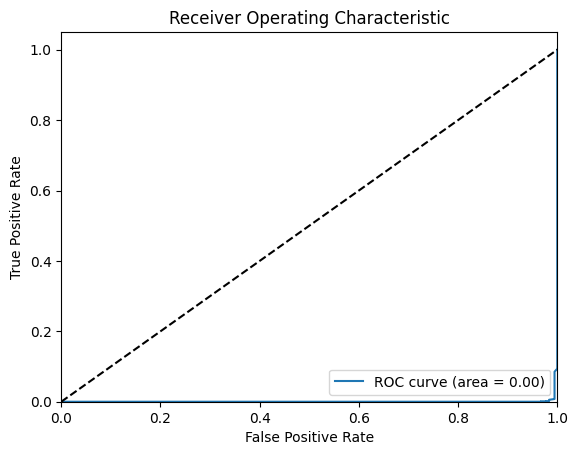

PR AUC: 0.7946639692558218


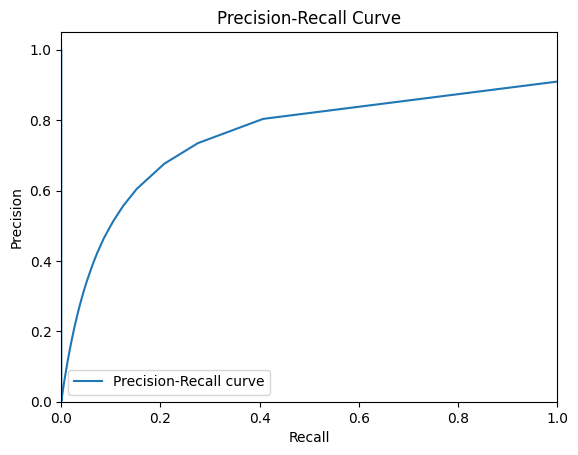

 54%|█████▍    | 7/13 [00:12<00:10,  1.81s/it]


Confusion Matrix:
 [[1819    0]
 [   1  180]]


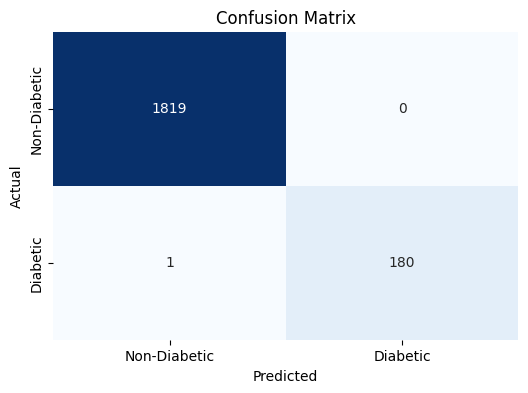


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.5186536224444819e-06


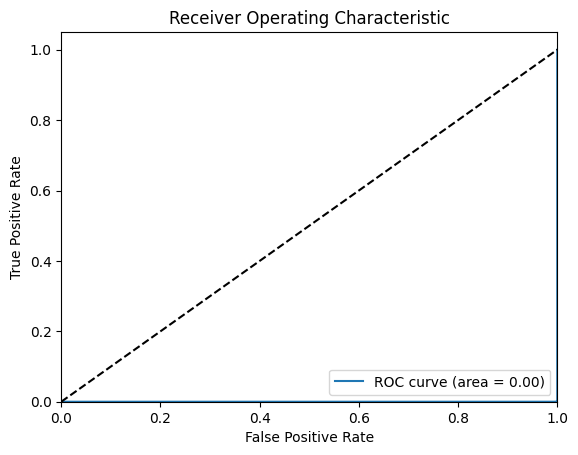

PR AUC: 0.7741748043306835


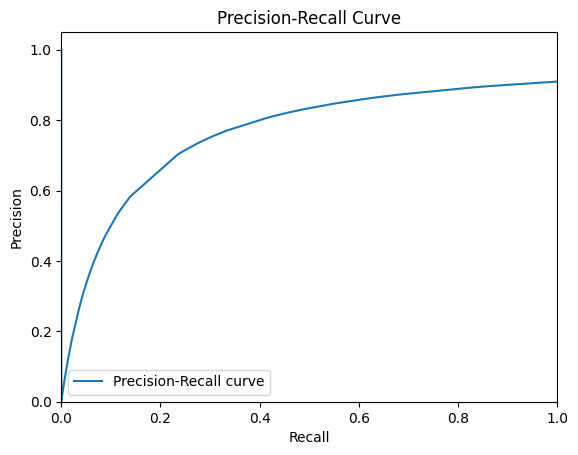

 62%|██████▏   | 8/13 [00:13<00:08,  1.74s/it]


Confusion Matrix:
 [[1819    0]
 [   1  180]]


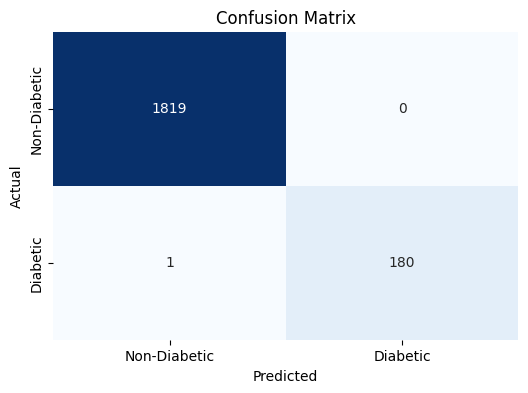


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.5186536224444819e-06


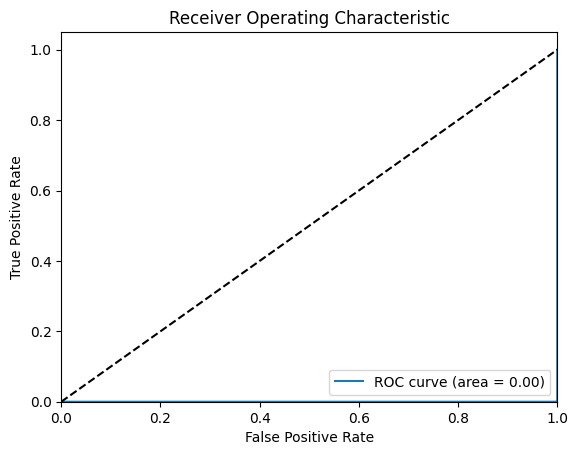

PR AUC: 0.765028334890364


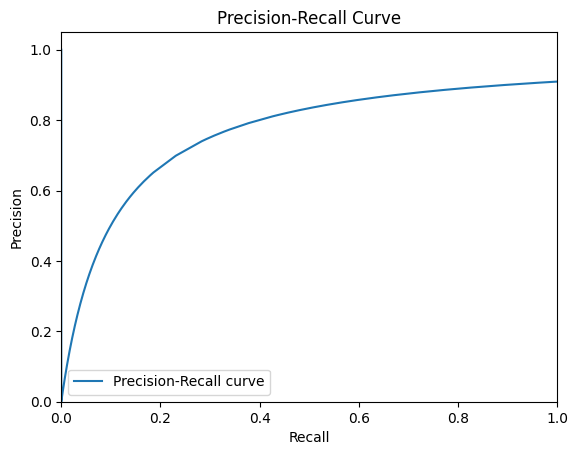

 69%|██████▉   | 9/13 [00:15<00:07,  1.78s/it]


Confusion Matrix:
 [[1819    0]
 [   1  180]]


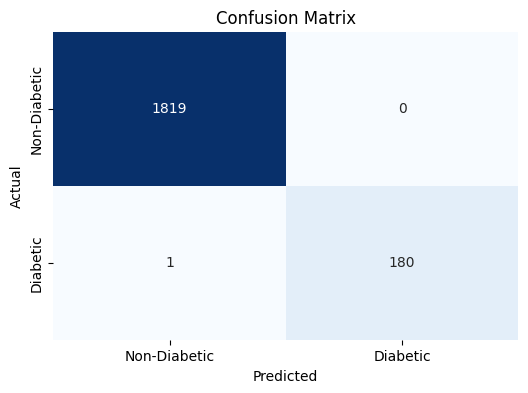


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 3.0373072448889638e-06


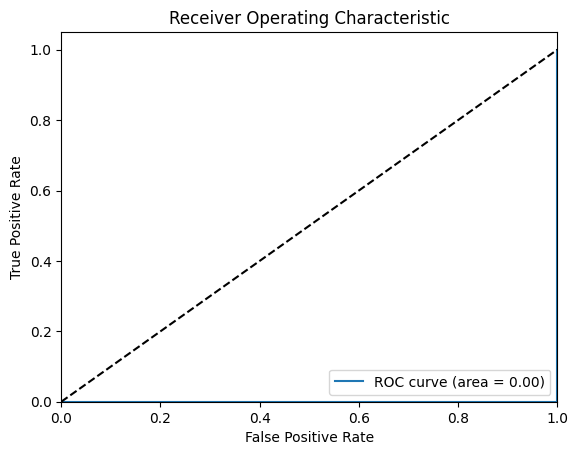

PR AUC: 0.8310577951738504


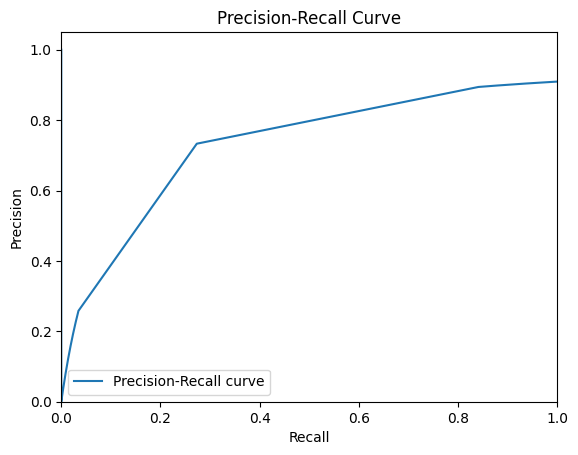

 77%|███████▋  | 10/13 [00:17<00:05,  1.79s/it]


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['Diabetic' 'Non-Diabetic']

In [47]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Non-Diabetic','Diabetic']
                ,yticklabels=['Non-Diabetic','Diabetic'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

    # Map target classes to numeric (1 for positive class 'Diabetic') for probability metric functions
    y_test_numeric = y_test.map({'Non-Diabetic': 0, 'Diabetic': 1})
    y_train_numeric = y_train.map({'Non-Diabetic': 0, 'Diabetic': 1})

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test_numeric, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test_numeric, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test_numeric, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test_numeric, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, pos_label='Diabetic'),
        "Test Precision": precision_score(y_test, test_pred, pos_label='Diabetic'),
        "Train Recall": recall_score(y_train, train_pred, pos_label='Diabetic'),
        "Test Recall": recall_score(y_test, test_pred, pos_label='Diabetic'),
        "Train F1 Score": f1_score(y_train, train_pred, pos_label='Diabetic'),
        "Test F1 Score": f1_score(y_test, test_pred, pos_label='Diabetic'),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

# **Voting Classification**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:59:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1819    0]
 [   1  180]]


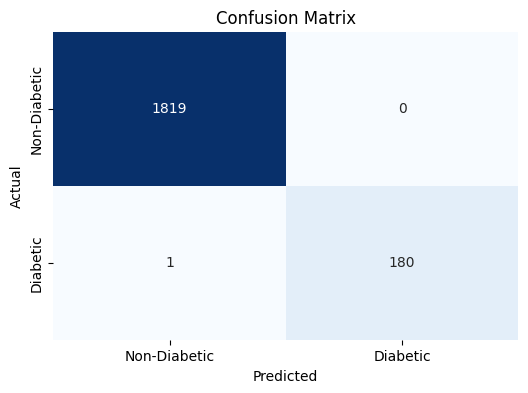


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.0006590956721409051


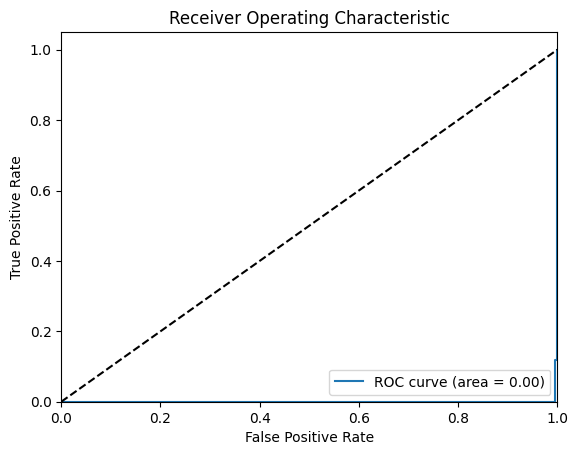

PR AUC: 0.7613321318634214


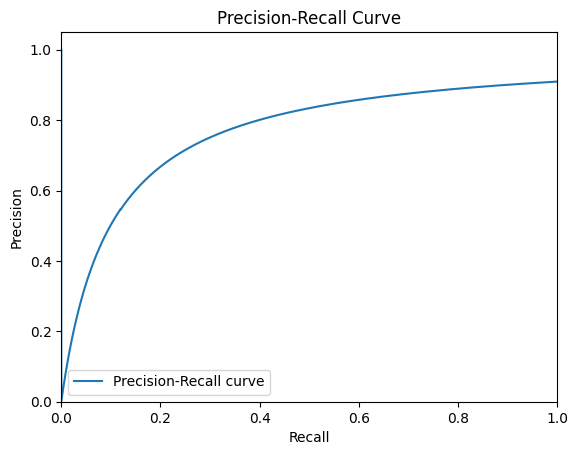

In [49]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Non-Diabetic','Diabetic']
            ,yticklabels=['Non-Diabetic','Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

# Map target classes to numeric (1 for positive class 'Diabetic') for probability metric functions
y_test_numeric = y_test.map({'Non-Diabetic': 0, 'Diabetic': 1})
y_train_numeric = y_train.map({'Non-Diabetic': 0, 'Diabetic': 1})

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test_numeric, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test_numeric, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test_numeric, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test_numeric, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, pos_label='Diabetic'),
    "Test Precision": precision_score(y_test, voting_test_pred, pos_label='Diabetic'),
    "Train Recall": recall_score(y_train, voting_train_pred, pos_label='Diabetic'),
    "Test Recall": recall_score(y_test, voting_test_pred, pos_label='Diabetic'),
    "Train F1 Score": f1_score(y_train, voting_train_pred, pos_label='Diabetic'),
    "Test F1 Score": f1_score(y_test, voting_test_pred, pos_label='Diabetic'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

# **Stacking Classification**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:00:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1819    0]
 [   1  180]]


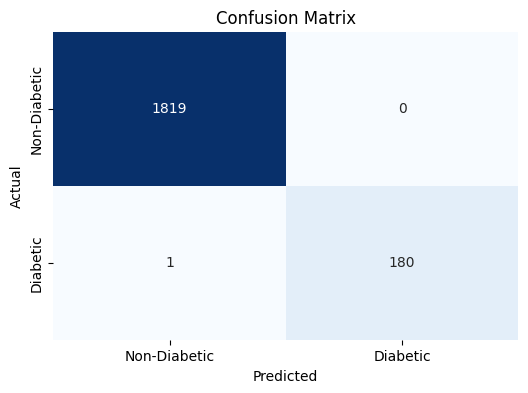


Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00      1819
    Diabetic       1.00      0.99      1.00       181

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.00011845498255066957


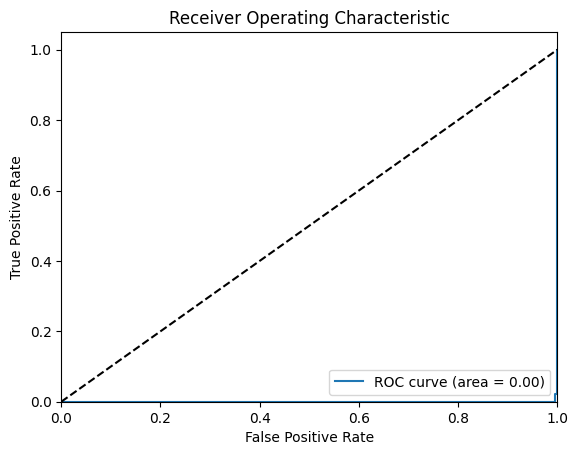

PR AUC: 0.8093347846706546


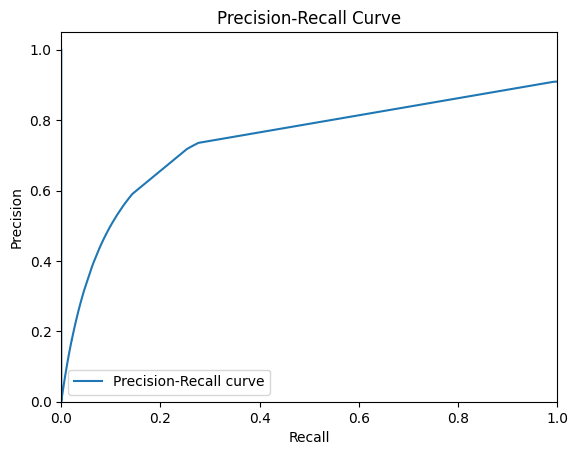

In [51]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train using correct lowercase variable names
stack_auto.fit(x_train, y_train)

# Predictions using correct lowercase variable names
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Non-Diabetic','Diabetic']
            ,yticklabels=['Non-Diabetic','Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Non-Diabetic','Diabetic'],zero_division=0))

# Map target classes to numeric (1 for positive class 'Diabetic') for probability metric functions
y_test_numeric = y_test.map({'Non-Diabetic': 0, 'Diabetic': 1})
y_train_numeric = y_train.map({'Non-Diabetic': 0, 'Diabetic': 1})

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test_numeric, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test_numeric, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test_numeric, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test_numeric, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, pos_label='Diabetic'),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, pos_label='Diabetic'),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, pos_label='Diabetic'),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, pos_label='Diabetic'),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, pos_label='Diabetic'),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, pos_label='Diabetic'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [52]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [53]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Gradient Boosting,1.000000,0.9995,1.000000,0.999451,1.000000,1.000000,1.000000,0.999725,1.000000,0.997238,0.000002,0.765028
Hist Gradient Boosting,1.000000,0.9995,1.000000,0.999451,1.000000,1.000000,1.000000,0.999725,1.000000,0.997238,0.000003,0.831058
AdaBoost,0.999750,0.9995,0.999727,0.999451,1.000000,1.000000,0.999864,0.999725,0.998514,0.997238,0.000002,0.774175
Random Forest,1.000000,0.9995,1.000000,0.999451,1.000000,1.000000,1.000000,0.999725,1.000000,0.997238,0.000796,0.834417
Voting Classifier,0.999750,0.9995,0.999727,0.999451,1.000000,1.000000,0.999864,0.999725,0.998514,0.997238,0.000659,0.761332
Stacking Classifier,1.000000,0.9995,1.000000,0.999451,1.000000,1.000000,1.000000,0.999725,1.000000,0.997238,0.000118,0.809335
Decision Tree,1.000000,0.9985,1.000000,0.999450,1.000000,0.998900,1.000000,0.999175,1.000000,0.996688,0.003312,0.908512
Extra Trees,1.000000,0.9965,1.000000,0.996166,1.000000,1.000000,1.000000,0.998080,1.000000,0.980663,0.000589,0.794664
Naive Bayes,0.990875,0.9895,0.990135,0.988587,1.000000,1.000000,0.995043,0.994261,0.945765,0.941989,0.001230,0.761365
SVC,0.975000,0.9765,0.982402,0.983097,0.990446,0.991204,0.986408,0.987134,0.898641,0.909967,0.005859,0.773724


<Axes: >

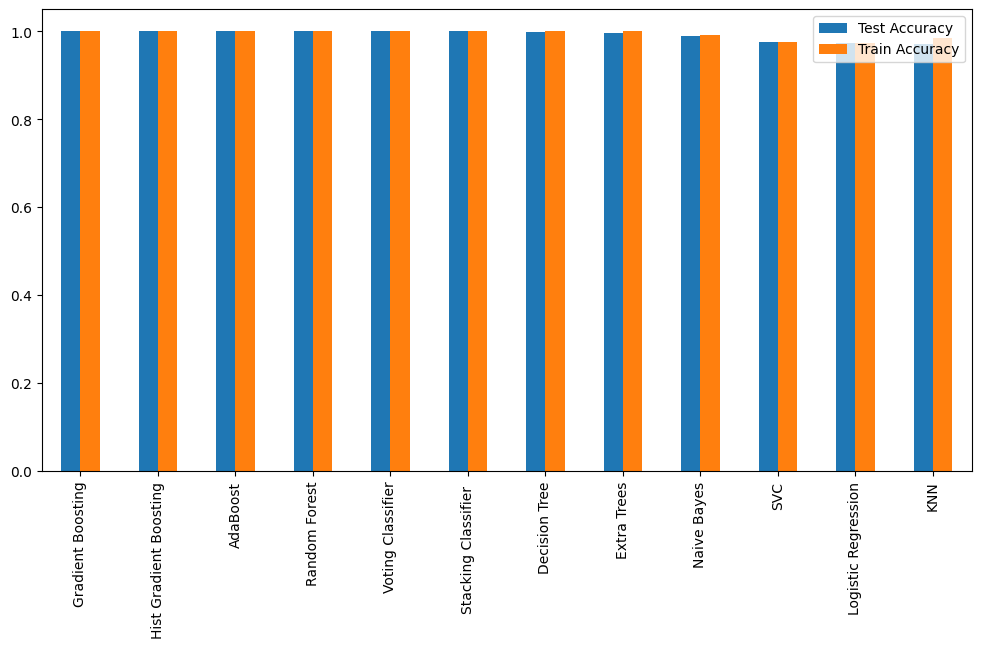

In [54]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

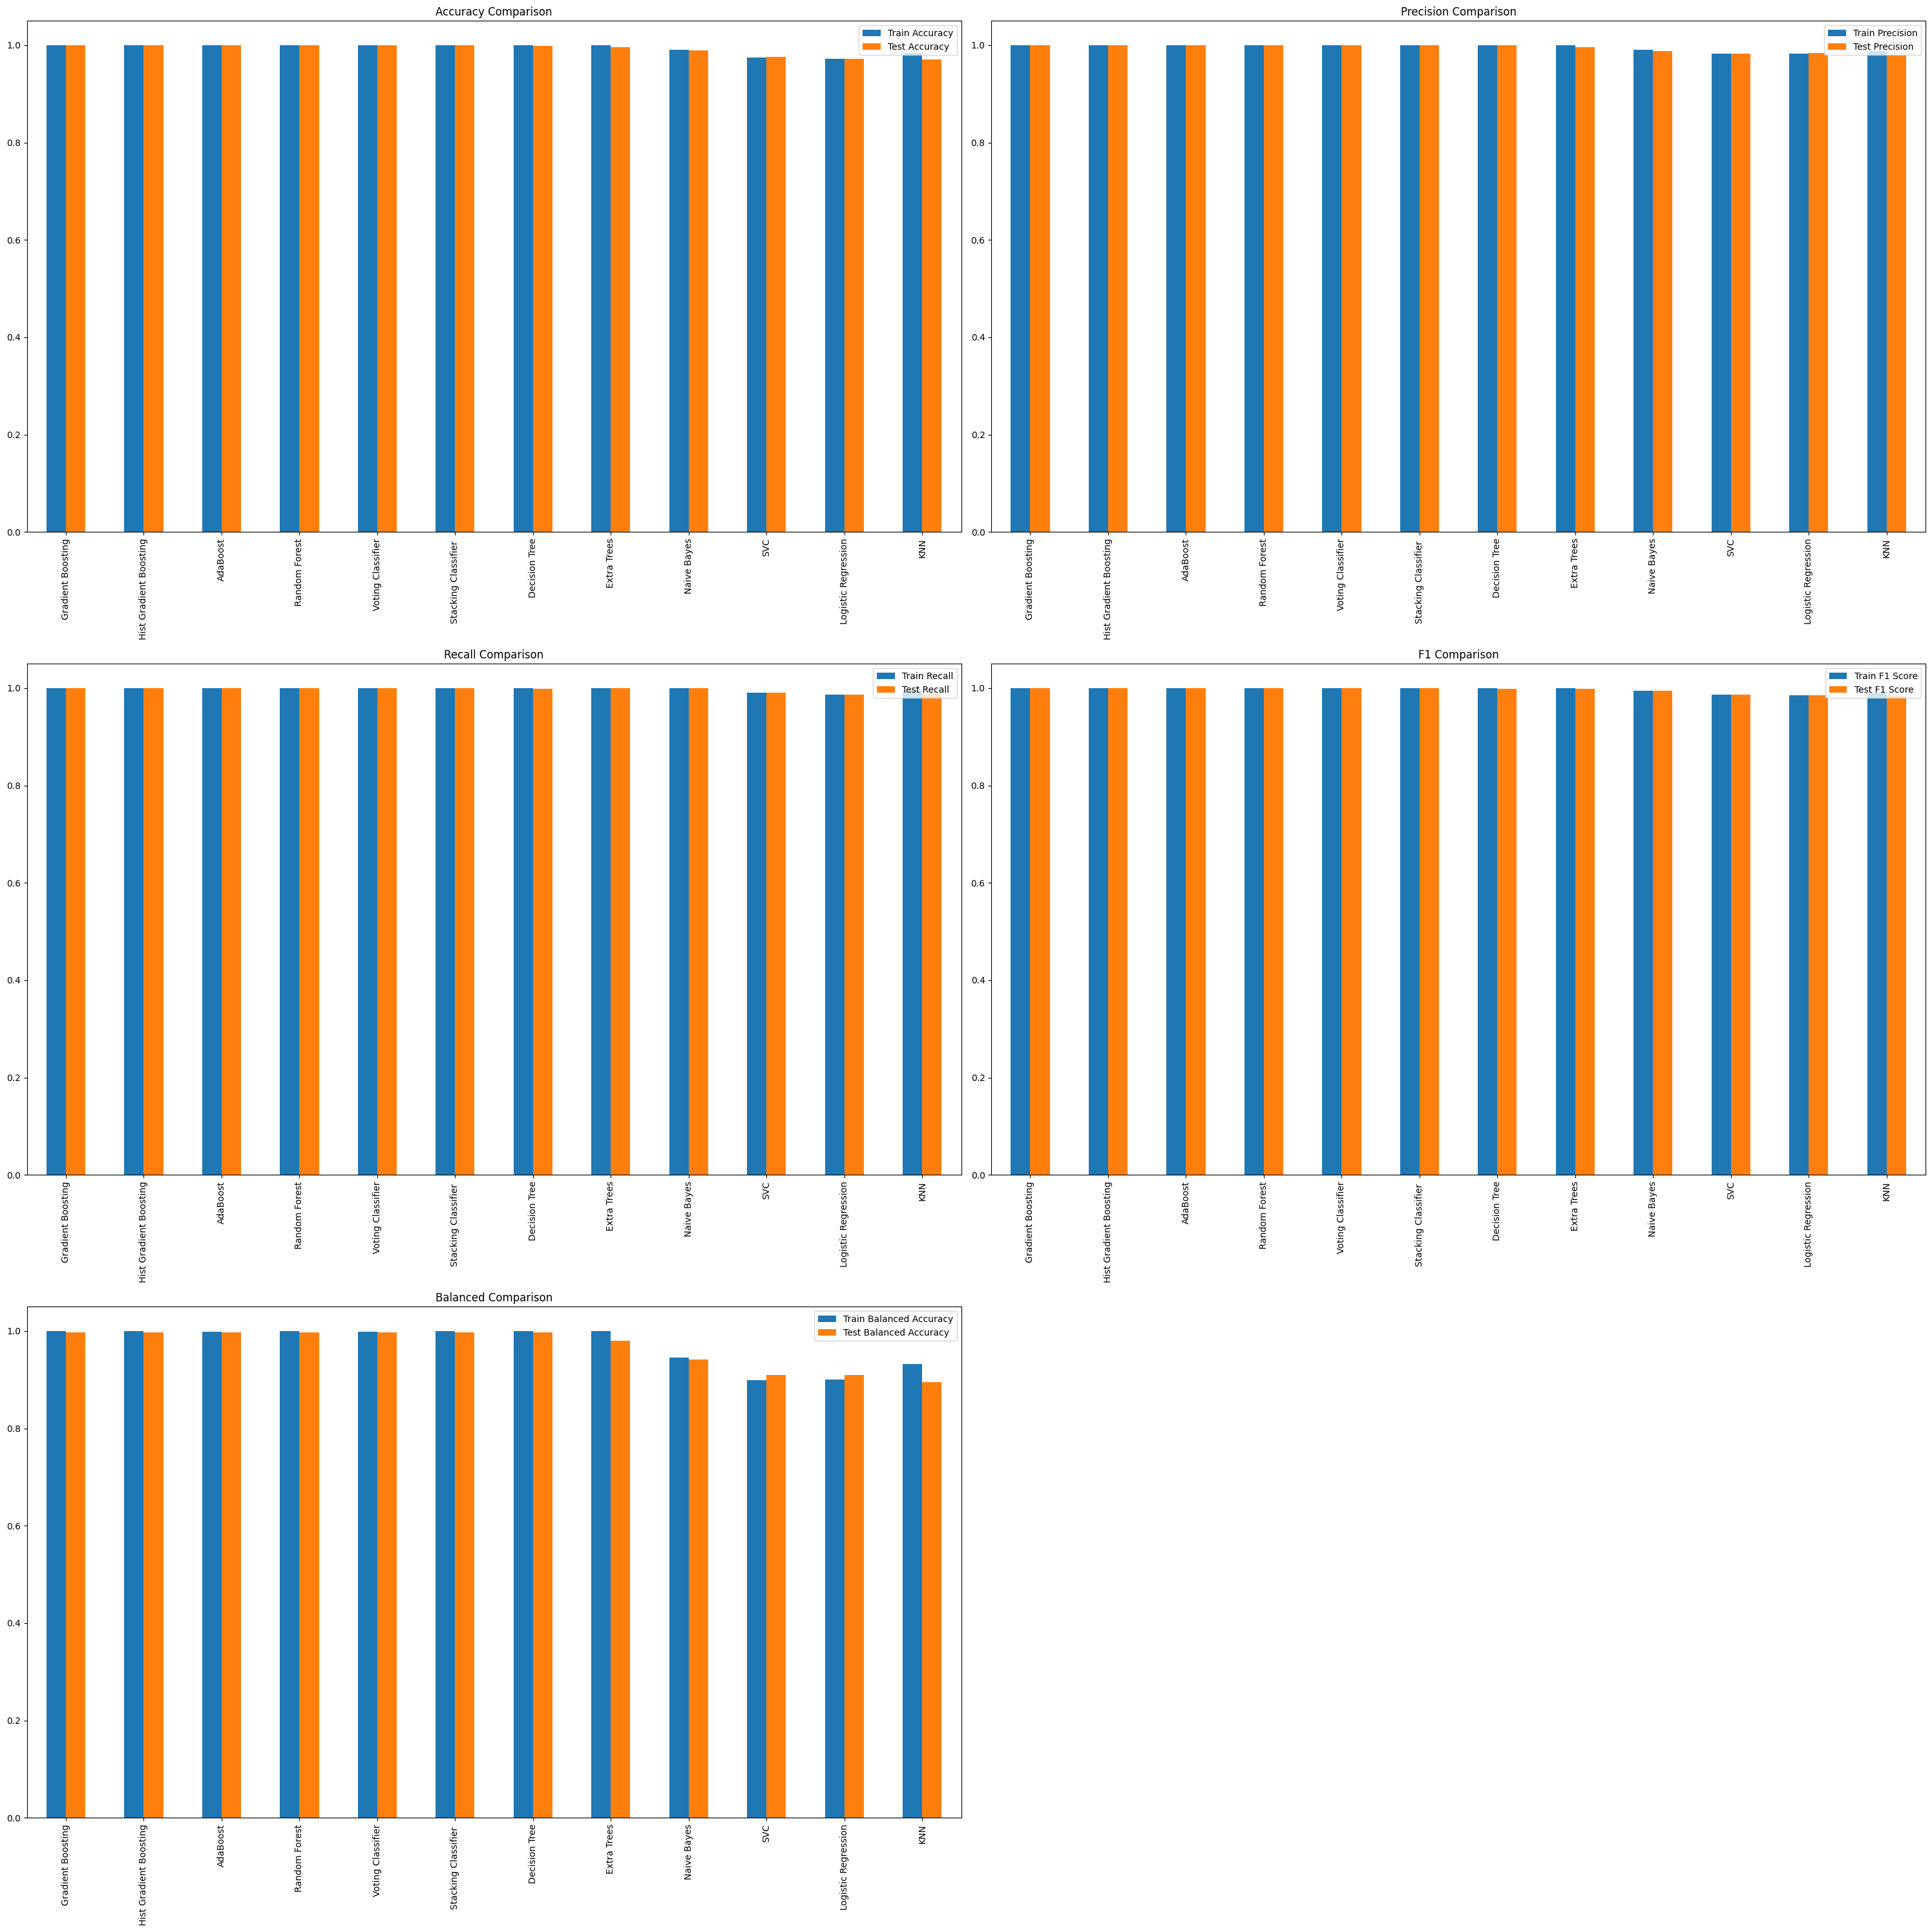

In [55]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()